In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from src.utils import (PROCESSED_DIR, METRIC_DIR, save_fig, save_table,
                       log_experiment, RANDOM_STATE)

sns.set_theme(style="whitegrid")

df = pd.read_parquet(PROCESSED_DIR / "cicids2017_clean.parquet")
feature_cols = [c for c in df.columns if c not in ("Label", "Label_Group")]
print("Rows:", f"{len(df):,}", "| Features:", len(feature_cols))

Mounted at /content/drive
Rows: 2,497,980 | Features: 69


In [2]:
# Experiment A: binary (BENIGN = 0, ATTACK = 1)
df["Binary"] = (df["Label"] != "BENIGN").astype("int8")

# Experiment B: multi-class on the 10 categories (Label_Group)
classes = sorted(df["Label_Group"].unique())
label_mapping = {name: i for i, name in enumerate(classes)}
with open(METRIC_DIR / "label_mapping.json", "w") as f:
    json.dump(label_mapping, f, indent=2)

print("Experiment A (binary) target counts:")
print(df["Binary"].value_counts().rename({0: "BENIGN (0)", 1: "ATTACK (1)"}))
print("\nExperiment B (multi-class) label mapping:")
print(label_mapping)

Experiment A (binary) target counts:
Binary
BENIGN (0)    2072254
ATTACK (1)     425726
Name: count, dtype: int64

Experiment B (multi-class) label mapping:
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS': 3, 'FTP-Patator': 4, 'Heartbleed': 5, 'Infiltration': 6, 'PortScan': 7, 'SSH-Patator': 8, 'Web Attack': 9}


In [3]:
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["Label_Group"], random_state=RANDOM_STATE
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

summary = pd.DataFrame({
    "train_count": train_df["Label_Group"].value_counts(),
    "test_count": test_df["Label_Group"].value_counts(),
})
summary["train_percent"] = (summary["train_count"] / len(train_df) * 100).round(3)
summary["test_percent"] = (summary["test_count"] / len(test_df) * 100).round(3)
print("Train rows:", f"{len(train_df):,}", "| Test rows:", f"{len(test_df):,}")
print(summary)

print("\nBinary share of ATTACK  train:", round(train_df["Binary"].mean() * 100, 2),
      "%  test:", round(test_df["Binary"].mean() * 100, 2), "%")

save_table(summary, "03_train_test_split_summary")
train_df.to_parquet(PROCESSED_DIR / "train.parquet", index=False)
test_df.to_parquet(PROCESSED_DIR / "test.parquet", index=False)
print("\n[saved] train.parquet and test.parquet")

log_experiment(
    experiment_id="EXP-00_split", task="both (binary + multi-class)",
    model="n/a (data split)", features=f"all {len(feature_cols)}",
    preprocessing="cleaned data (duplicates, NaN/inf, constant columns removed); no scaling yet",
    hyperparameters={"test_size": 0.2, "stratify": "Label_Group", "random_state": RANDOM_STATE},
    split="80/20 stratified on Label_Group",
    metrics={"train_rows": len(train_df), "test_rows": len(test_df)},
    notes="Test set locked until final evaluation.",
)

del df   # free memory

Train rows: 1,998,384 | Test rows: 499,596
              train_count  test_count  train_percent  test_percent
Label_Group                                                       
BENIGN            1657803      414451         82.957        82.957
DoS                154984       38746          7.755         7.755
DDoS               102411       25603          5.125         5.125
PortScan            72555       18139          3.631         3.631
FTP-Patator          4745        1186          0.237         0.237
SSH-Patator          2575         644          0.129         0.129
Web Attack           1715         428          0.086         0.086
Bot                  1558         390          0.078         0.078
Infiltration           29           7          0.001         0.001
Heartbleed              9           2          0.000         0.000

Binary share of ATTACK  train: 17.04 %  test: 17.04 %
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/03_train_test_split_summa

In [4]:
from sklearn.feature_selection import mutual_info_classif

CAP = 10_000
sel_sample = (train_df.sample(frac=1, random_state=RANDOM_STATE)
                      .groupby("Label_Group").head(CAP))
sel_y = sel_sample["Label_Group"].map(label_mapping)
print("Selection sample:", f"{len(sel_sample):,}", "rows")
print(sel_sample["Label_Group"].value_counts())

mi = mutual_info_classif(sel_sample[feature_cols], sel_y,
                         discrete_features=False, random_state=RANDOM_STATE)
mi_series = pd.Series(mi, index=feature_cols).sort_values(ascending=False)
print("\nTop 15 by mutual information:")
print(mi_series.head(15).round(3))

Selection sample: 50,631 rows
Label_Group
DDoS            10000
BENIGN          10000
DoS             10000
PortScan        10000
FTP-Patator      4745
SSH-Patator      2575
Web Attack       1715
Bot              1558
Infiltration       29
Heartbleed          9
Name: count, dtype: int64

Top 15 by mutual information:
Average Packet Size            1.648
Packet Length Mean             1.623
Packet Length Std              1.537
Packet Length Variance         1.530
Total Length of Fwd Packets    1.481
Subflow Fwd Bytes              1.479
Init_Win_bytes_backward        1.451
Fwd Header Length              1.422
Total Length of Bwd Packets    1.403
Subflow Bwd Bytes              1.401
Fwd Packet Length Max          1.401
Bwd Packet Length Mean         1.388
Avg Bwd Segment Size           1.385
Max Packet Length              1.378
Bwd Packet Length Max          1.360
dtype: float64


In [5]:
THRESH = 0.95

corr_sample = train_df[feature_cols].sample(300_000, random_state=RANDOM_STATE)
corr_abs = corr_sample.corr().abs()

kept, dropped = [], []
for col in mi_series.index:            # go from most to least informative
    partner = next((k for k in kept if corr_abs.loc[col, k] >= THRESH), None)
    if partner is None:
        kept.append(col)
    else:
        dropped.append([col, partner, round(float(corr_abs.loc[col, partner]), 3)])

dropped_df = pd.DataFrame(dropped, columns=["dropped_feature", "kept_instead", "correlation"])
print("ALL features:", len(feature_cols))
print("After correlation filter:", len(kept), "| dropped:", len(dropped))
print(dropped_df.to_string(index=False))
save_table(dropped_df, "03_correlation_filter_dropped", index=False)

ALL features: 69
After correlation filter: 48 | dropped: 21
       dropped_feature                kept_instead  correlation
    Packet Length Mean         Average Packet Size        0.998
     Subflow Fwd Bytes Total Length of Fwd Packets        1.000
     Subflow Bwd Bytes Total Length of Bwd Packets        1.000
  Avg Bwd Segment Size      Bwd Packet Length Mean        1.000
     Max Packet Length           Packet Length Std        0.984
 Bwd Packet Length Max      Bwd Packet Length Mean        0.958
          Flow IAT Max                 Fwd IAT Max        0.998
  Avg Fwd Segment Size      Fwd Packet Length Mean        1.000
         Fwd IAT Total               Flow Duration        0.999
         Fwd Packets/s              Flow Packets/s        0.981
 Fwd Packet Length Std       Fwd Packet Length Max        0.967
   Subflow Bwd Packets Total Length of Bwd Packets        0.995
Total Backward Packets Total Length of Bwd Packets        0.995
     Total Fwd Packets Total Length of Bwd P

SELECTED set (25 features), best first:
 1. Average Packet Size
 2. Init_Win_bytes_backward
 3. Total Length of Fwd Packets
 4. Fwd Packet Length Max
 5. Destination Port
 6. Bwd Packet Length Mean
 7. Fwd Header Length
 8. Total Length of Bwd Packets
 9. Packet Length Variance
10. Packet Length Std
11. Bwd Header Length
12. Fwd Packet Length Mean
13. Flow Duration
14. Fwd IAT Max
15. Flow Bytes/s
16. Bwd Packet Length Std
17. Bwd Packets/s
18. Init_Win_bytes_forward
19. act_data_pkt_fwd
20. Fwd IAT Std
21. Flow Packets/s
22. Flow IAT Std
23. Bwd IAT Total
24. Bwd Packet Length Min
25. Bwd IAT Std
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/03_feature_selection_scores.csv
[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/03_feature_selection_scores.png


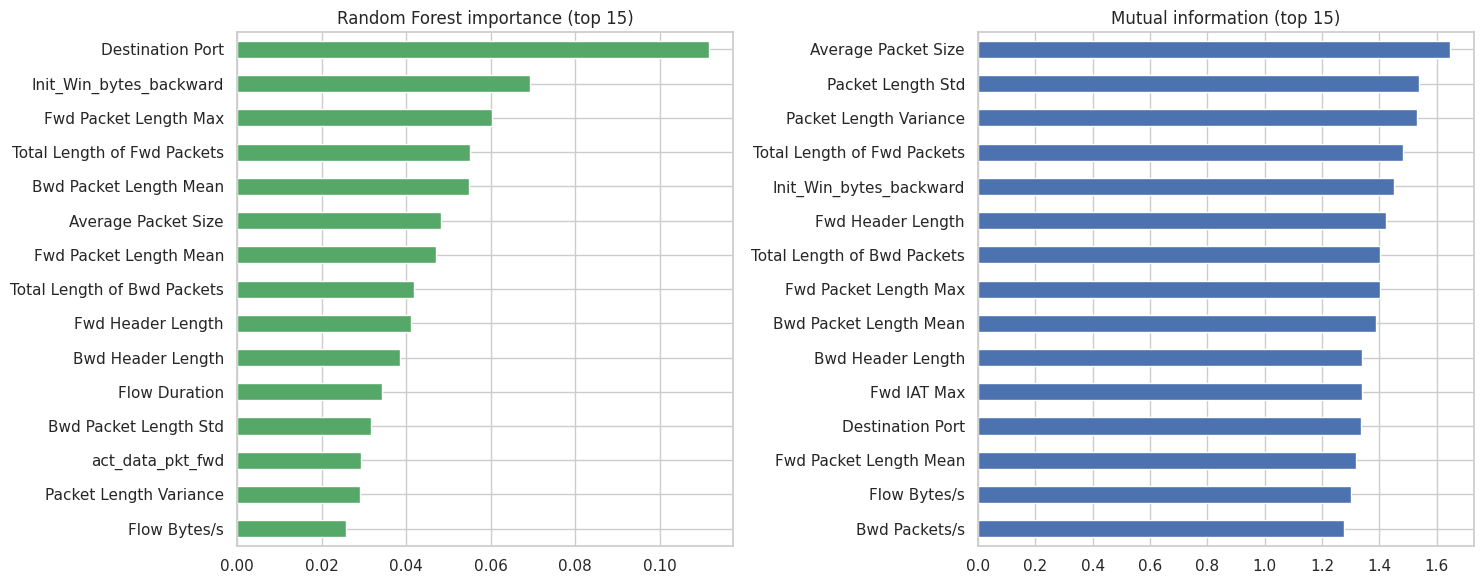

[logged experiment] EXP-01_feature_selection


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE

K = 25   # size of the SELECTED set
Xc = sel_sample[kept]

# Random Forest importance
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(Xc, sel_y)
rf_imp = pd.Series(rf.feature_importances_, index=kept)

# Recursive feature elimination
rfe = RFE(RandomForestClassifier(n_estimators=50, max_depth=12,
                                 class_weight="balanced_subsample",
                                 n_jobs=-1, random_state=RANDOM_STATE),
          n_features_to_select=K, step=3)
rfe.fit(Xc, sel_y)
rfe_rank = pd.Series(rfe.ranking_, index=kept)

# Consensus of the three rankings
scores = pd.DataFrame({"mutual_info": mi_series[kept],
                       "rf_importance": rf_imp,
                       "rfe_rank": rfe_rank})
scores["rank_mi"] = scores["mutual_info"].rank(ascending=False, method="min")
scores["rank_rf"] = scores["rf_importance"].rank(ascending=False, method="min")
scores["rank_rfe"] = scores["rfe_rank"].rank(ascending=True, method="min")
scores["avg_rank"] = scores[["rank_mi", "rank_rf", "rank_rfe"]].mean(axis=1)
scores = scores.sort_values("avg_rank")
selected = scores.head(K).index.tolist()

print(f"SELECTED set ({K} features), best first:")
for i, c in enumerate(selected, 1):
    print(f"{i:2d}. {c}")

save_table(scores.round(4), "03_feature_selection_scores")

# Save the three feature sets for later notebooks
feature_sets = {
    "ALL": feature_cols,
    "CORR_FILTERED": kept,
    "SELECTED": selected,
    "settings": {"corr_threshold": THRESH, "selected_k": K,
                 "selection_sample_cap_per_class": CAP, "random_state": RANDOM_STATE},
}
with open(METRIC_DIR / "feature_sets.json", "w") as f:
    json.dump(feature_sets, f, indent=2)

# Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
rf_imp.sort_values(ascending=False).head(15)[::-1].plot.barh(ax=axes[0], color="#55A868")
axes[0].set_title("Random Forest importance (top 15)")
mi_series[kept].sort_values(ascending=False).head(15)[::-1].plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_title("Mutual information (top 15)")
save_fig("03_feature_selection_scores")
plt.show()

log_experiment(
    experiment_id="EXP-01_feature_selection", task="multi-class (Label_Group)",
    model="MI + correlation filter + RF importance + RFE",
    features=f"ALL={len(feature_cols)}, CORR_FILTERED={len(kept)}, SELECTED={K}",
    preprocessing="training rows only; class-balanced sample, up to 10,000 per class",
    hyperparameters={"corr_threshold": THRESH, "K": K}, split="train set only",
    metrics={"n_selected": K}, notes="Feature sets saved to results/metrics/feature_sets.json",
)

In [7]:
from src.utils import PROCESSED_DIR, METRIC_DIR

for p in [PROCESSED_DIR / "train.parquet", PROCESSED_DIR / "test.parquet",
          METRIC_DIR / "label_mapping.json", METRIC_DIR / "feature_sets.json"]:
    print(f"{p.name:22s} {p.stat().st_size/1e6:8.1f} MB")

train.parquet             233.9 MB
test.parquet               59.9 MB
label_mapping.json          0.0 MB
feature_sets.json           0.0 MB
